In [49]:
import h5py
import pylab as plt
import numpy as np
from matplotlib.dates import num2date
from datetime import datetime
import pytz

# Load Samples Data

In [50]:
hdf_samples = h5py.File('../data/validation/csextent_samples.h5')
print(hdf_samples.keys())
lat_extent_samples = hdf_samples['lat_extent'][:].squeeze()
times_d2n = hdf_samples['times_d2n'][:]
hdf_samples.close()

<KeysViewHDF5 ['contexts', 'lat_extent', 'lat_max', 'lat_min', 'lats', 'lons', 'radius', 'times_d2n']>


In [51]:
lat_extent_samples.shape

(835,)

In [52]:
times_samples = np.array(num2date(times_d2n))

# Load Training Data

In [53]:
hdf_samples = h5py.File('../data/validation/csextent_testdata.h5')
print(hdf_samples.keys())
lat_extent_testdata = hdf_samples['lat_extent'][:].squeeze()
hdf_samples.close()

<KeysViewHDF5 ['lat_extent', 'lat_max', 'lat_min', 'lats', 'lons', 'matched_wsa_time_iso', 'radius', 'times_d2n']>


In [54]:
lat_extent_testdata.shape

(835,)

# Plot Experiment

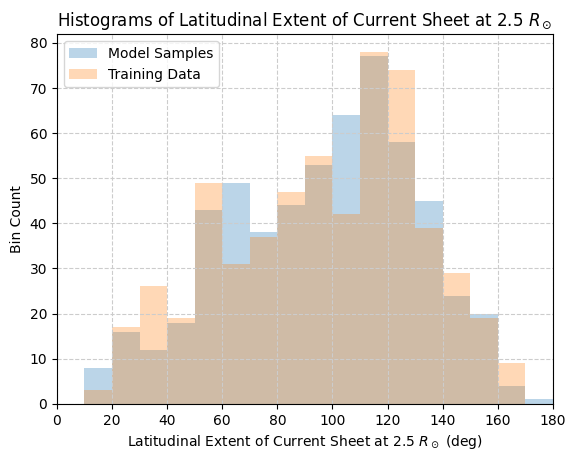

In [55]:
bins = np.arange(0, 181, 10)
cutoff = datetime(2021, 1, 1).replace(tzinfo=pytz.utc)

plt.hist(lat_extent_samples[times_samples < cutoff], bins=bins, label='Model Samples', alpha=0.3)
plt.hist(lat_extent_testdata[times_samples < cutoff], bins=bins, label='Training Data', alpha=0.3)

plt.legend()
plt.ylabel('Bin Count')
plt.xlabel(r'Latitudinal Extent of Current Sheet at 2.5 $R_\odot$ (deg)')
plt.title('Histograms of Latitudinal Extent of Current Sheet at 2.5 $R_\odot$')
plt.xlim(0, 180)
plt.grid(linestyle='dashed', color='#ccc')
plt.savefig('../plots/paper/csextent.png', dpi=300)

In [56]:
print('Samples')
print('---------')
print('Mean', np.mean(lat_extent_samples[times_samples < cutoff]))
print('STD', np.std(lat_extent_samples[times_samples < cutoff]))
print()
print('Training Data')
print('---------')
print('Mean', np.mean(lat_extent_testdata[times_samples < cutoff]))
print('STD', np.std(lat_extent_testdata[times_samples < cutoff]))
print()

Samples
---------
Mean 96.082886
STD 34.12857

Training Data
---------
Mean 96.488464
STD 34.904194

